# Cyclistic Bike-Share Analysis

## 1. Ask — Definición del problema

**Problema de negocio:** Cyclistic busca aumentar la cantidad de miembros anuales mediante estrategias de marketing fundamentadas en datos.

**Pregunta principal:** ¿Cómo utilizan las bicicletas de Cyclistic los miembros anuales y los usuarios casuales de manera diferente?

**Objetivo del análisis:** Identificar y comparar los patrones de uso de ambos grupos para desarrollar tres recomendaciones comerciales que contribuyan a orientar las estrategias de conversión de usuarios casuales en miembros anuales.

**Stakeholders:** Lily Moreno, directora de marketing; equipo de análisis de marketing; y equipo ejecutivo de Cyclistic.

## 2. Prepare — Preparación de los datos

### Fuente de datos

Se utilizaron registros históricos de viajes del sistema Divvy de Chicago, proporcionados como conjunto de datos para el caso de estudio de Cyclistic.

El análisis comprende 12 archivos CSV mensuales correspondientes al período de octubre de 2025 a septiembre de 2026.

### Organización de los datos

Cada fila representa un viaje individual e incluye información sobre el tipo de usuario (`member_casual`), las fechas y horas de inicio y finalización, el tipo de bicicleta y las estaciones de origen y destino.

Los registros permiten comparar patrones de uso, pero no identificar usuarios únicos ni determinar directamente qué viajes corresponden a una misma persona.

### Exploración inicial — Octubre de 2025

Se comenzó examinando el archivo correspondiente a octubre de 2025 para conocer la estructura del conjunto de datos, revisar sus columnas, identificar tipos de datos y realizar las primeras comprobaciones.

In [1]:
import pandas as pd
import numpy as np

print("¡Python y pandas funcionan!")
print("Versión de pandas:", pd.__version__)

¡Python y pandas funcionan!
Versión de pandas: 3.1.0


In [2]:
octubre = pd.read_csv("../data/raw/202510-divvy-tripdata.csv")

In [3]:
octubre.head(5)

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,AAED255E1310E516,classic_bike,2025-10-27 08:19:53.208,2025-10-27 08:25:53.481,Wells St & Polk St,CHI00606,Franklin St & Washington St,CHI02074,41.872732,-87.633516,41.883180,-87.635110,member
1,F90C86BF3BB85040,classic_bike,2025-10-14 07:42:55.465,2025-10-14 08:04:08.663,Racine Ave & Wrightwood Ave,CHI00506,McClurg Ct & Ohio St,CHI00330,41.928887,-87.658971,41.892592,-87.617289,member
2,90429D9729A3EE8E,classic_bike,2025-10-12 08:18:23.613,2025-10-12 08:28:38.983,Clinton St & 18th St,CHI00235,Desplaines St & Jackson Blvd,CHI00518,41.857950,-87.640826,41.878119,-87.643948,casual
3,C8433F9B78A1E63D,electric_bike,2025-10-14 07:45:56.471,2025-10-14 08:07:24.447,Pine Grove Ave & Irving Park Rd,CHI00482,Wells St & Huron St,CHI00294,41.954398,-87.647997,41.894795,-87.634374,member
4,62F3C413C442C154,electric_bike,2025-10-19 10:08:45.138,2025-10-19 10:12:34.771,Pine Grove Ave & Irving Park Rd,CHI00482,Sheridan Rd & Montrose Ave,CHI00290,41.954365,-87.647929,41.961670,-87.654640,member


In [4]:
octubre.shape

(646039, 13)

In [5]:
octubre.info()

<class 'pandas.DataFrame'>
RangeIndex: 646039 entries, 0 to 646038
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   ride_id             646039 non-null  str    
 1   rideable_type       646039 non-null  str    
 2   started_at          646039 non-null  str    
 3   ended_at            646039 non-null  str    
 4   start_station_name  501060 non-null  str    
 5   start_station_id    501060 non-null  str    
 6   end_station_name    492573 non-null  str    
 7   end_station_id      492573 non-null  str    
 8   start_lat           646039 non-null  float64
 9   start_lng           646039 non-null  float64
 10  end_lat             645453 non-null  float64
 11  end_lng             645453 non-null  float64
 12  member_casual       646039 non-null  str    
dtypes: float64(4), str(9)
memory usage: 64.1 MB


In [6]:
octubre.member_casual.value_counts()

member_casual
member    422029
casual    224010
Name: count, dtype: int64

In [7]:
octubre.member_casual.value_counts(normalize=True) *100

member_casual
member    65.325623
casual    34.674377
Name: proportion, dtype: float64

### Resultado preliminar — Distribución de viajes en octubre de 2025

Durante octubre de 2025, el 65,33 % de los viajes correspondió a miembros anuales y el 34,67 % a usuarios casuales.

Este resultado corresponde exclusivamente al mes explorado y no debe interpretarse como la distribución del período anual completo.

Los datos representan viajes, no usuarios únicos, ya que una misma persona pudo realizar varios viajes.

In [8]:
noviembre = pd.read_csv("../data/raw/202511-divvy-tripdata.csv")

In [9]:
noviembre.head(5)


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,E555D9F8E9C2F56B,electric_bike,2025-11-04 00:09:07.792,2025-11-04 00:15:04.661,NaN,NaN,NaN,NaN,41.94,-87.67,41.94,-87.67,casual
1,EAEBE70DBF015886,electric_bike,2025-11-04 14:32:09.067,2025-11-04 14:36:43.998,NaN,NaN,NaN,NaN,41.90,-87.64,41.91,-87.64,casual
2,A42F8404F804E56E,electric_bike,2025-11-04 12:20:48.215,2025-11-04 12:21:01.630,NaN,NaN,NaN,NaN,41.89,-87.63,41.89,-87.63,casual
3,E49D01E38A1E074E,electric_bike,2025-11-04 12:17:16.548,2025-11-04 12:17:51.527,NaN,NaN,NaN,NaN,41.89,-87.63,41.89,-87.63,casual
4,9308F609195D2414,electric_bike,2025-11-04 08:16:27.979,2025-11-04 08:21:02.780,NaN,NaN,NaN,NaN,41.89,-87.64,41.88,-87.64,casual


In [10]:
noviembre.shape

(356628, 13)

In [11]:
noviembre.info()

<class 'pandas.DataFrame'>
RangeIndex: 356628 entries, 0 to 356627
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   ride_id             356628 non-null  str    
 1   rideable_type       356628 non-null  str    
 2   started_at          356628 non-null  str    
 3   ended_at            356628 non-null  str    
 4   start_station_name  280348 non-null  str    
 5   start_station_id    280348 non-null  str    
 6   end_station_name    274732 non-null  str    
 7   end_station_id      274732 non-null  str    
 8   start_lat           356628 non-null  float64
 9   start_lng           356628 non-null  float64
 10  end_lat             356271 non-null  float64
 11  end_lng             356271 non-null  float64
 12  member_casual       356628 non-null  str    
dtypes: float64(4), str(9)
memory usage: 35.4 MB


In [12]:
octubre.columns

Index(['ride_id', 'rideable_type', 'started_at', 'ended_at',
       'start_station_name', 'start_station_id', 'end_station_name',
       'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng',
       'member_casual'],
      dtype='str')

In [13]:
noviembre.columns

Index(['ride_id', 'rideable_type', 'started_at', 'ended_at',
       'start_station_name', 'start_station_id', 'end_station_name',
       'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng',
       'member_casual'],
      dtype='str')

In [14]:
octubre.columns.equals(noviembre.columns)

True

In [15]:
diciembre = pd.read_csv("../data/raw/202512-divvy-tripdata.csv")

In [16]:
diciembre.shape

(140534, 13)

In [17]:
diciembre.info()

<class 'pandas.DataFrame'>
RangeIndex: 140534 entries, 0 to 140533
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   ride_id             140534 non-null  str    
 1   rideable_type       140534 non-null  str    
 2   started_at          140534 non-null  str    
 3   ended_at            140534 non-null  str    
 4   start_station_name  113608 non-null  str    
 5   start_station_id    113608 non-null  str    
 6   end_station_name    110489 non-null  str    
 7   end_station_id      110489 non-null  str    
 8   start_lat           140534 non-null  float64
 9   start_lng           140534 non-null  float64
 10  end_lat             140412 non-null  float64
 11  end_lng             140412 non-null  float64
 12  member_casual       140534 non-null  str    
dtypes: float64(4), str(9)
memory usage: 13.9 MB


In [18]:
diciembre.columns.equals(octubre.columns)

True

In [19]:
from pathlib import Path
carpeta = Path("../data/raw")
archivos = sorted(carpeta.glob("*.csv"))

print (len(archivos))

12


In [20]:
import os

print(os.getcwd())
print(carpeta.resolve())
print(carpeta.exists())

C:\Users\Lea\Desktop\Work\Data Analyst\Cyclistic_Capstone\notebooks
C:\Users\Lea\Desktop\Work\Data Analyst\Cyclistic_Capstone\data\raw
True


In [21]:
for archivo in archivos:
    print(archivo.name)

202510-divvy-tripdata.csv
202511-divvy-tripdata.csv
202512-divvy-tripdata.csv
202601-divvy-tripdata.csv
202602-divvy-tripdata.csv
202603-divvy-tripdata.csv
202604-divvy-tripdata.csv
202605-divvy-tripdata.csv
202606-divvy-tripdata.csv
202607-divvy-tripdata.csv
202608-divvy-tripdata.csv
202609-divvy-tripdata.csv


In [22]:
enero = pd.read_csv("../data/raw/202601-divvy-tripdata.csv")

enero["started_at"].head(5)

0    2026-01-31 09:13:09.018
1    2026-01-15 14:25:42.526
2    2026-01-06 12:55:33.572
3    2026-01-26 16:22:25.011
4    2026-01-10 18:13:30.139
Name: started_at, dtype: str

In [23]:
enero["started_at"].min(), enero["started_at"].max()

('2025-12-31 10:30:49.482', '2026-01-31 23:56:54.069')

In [24]:
(enero["started_at"] < "2026-01-01").sum()

np.int64(23)

In [25]:
((enero["started_at"] >= "2026-01-01") & (enero["started_at"] < "2026-02-01")).sum()

np.int64(137764)

### Control de calidad — Inconsistencia en el archivo de enero de 2026

Durante la exploración de los archivos CSV, detectamos que el archivo identificado como `202501-divvy-tripdata.csv` contenía principalmente registros correspondientes a enero de 2026.

Al verificar la columna `started_at`, encontramos:

- **137.764 viajes** iniciados durante enero de 2026.
- **23 viajes** iniciados el 31 de diciembre de 2025.
- **137.787 registros** en total.

Después de comprobar las fechas, renombramos el archivo como `202601-divvy-tripdata.csv`.

Decidimos conservar provisionalmente los 23 registros de diciembre hasta verificar si también aparecen en el archivo correspondiente a ese mes, para evitar posibles duplicaciones.

Esta observación se tendrá en cuenta durante la fase de limpieza de datos (*Process*).

In [26]:
archivos = sorted(carpeta.glob("*.csv"))

In [27]:
for archivo in archivos:
    columnas = pd.read_csv(archivo, nrows=0).columns
    print(archivo.name, columnas.equals(octubre.columns))

202510-divvy-tripdata.csv True
202511-divvy-tripdata.csv True
202512-divvy-tripdata.csv True
202601-divvy-tripdata.csv True
202602-divvy-tripdata.csv True
202603-divvy-tripdata.csv True
202604-divvy-tripdata.csv True
202605-divvy-tripdata.csv True
202606-divvy-tripdata.csv True
202607-divvy-tripdata.csv True
202608-divvy-tripdata.csv True
202609-divvy-tripdata.csv True


In [28]:
meses_combinados = []
for archivo in archivos:
    df = pd.read_csv(archivo)
    meses_combinados.append(df)

In [29]:
len(meses_combinados)

12

In [30]:
viajes = pd.concat(meses_combinados, ignore_index=True)

In [31]:
viajes.shape

(6171785, 13)

In [32]:
sum(len(df) for df in meses_combinados)

6171785

In [33]:
del meses_combinados, octubre, noviembre, diciembre, enero, df

## 3. Process — Limpieza y transformación de datos

### Eliminación de registros duplicados

In [34]:
viajes.info()

<class 'pandas.DataFrame'>
RangeIndex: 6171785 entries, 0 to 6171784
Data columns (total 13 columns):
 #   Column              Dtype  
---  ------              -----  
 0   ride_id             str    
 1   rideable_type       str    
 2   started_at          str    
 3   ended_at            str    
 4   start_station_name  str    
 5   start_station_id    str    
 6   end_station_name    str    
 7   end_station_id      str    
 8   start_lat           float64
 9   start_lng           float64
 10  end_lat             float64
 11  end_lng             float64
 12  member_casual       str    
dtypes: float64(4), str(9)
memory usage: 612.1 MB


In [35]:
viajes["ride_id"].duplicated().sum()

np.int64(35)

In [36]:
viajes[viajes["ride_id"].duplicated(keep=False)].head(10)

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
1803398,D582320F33836B82,electric_bike,2026-04-30 23:55:35.449,2026-05-01 00:04:50.335,NaN,NaN,NaN,NaN,41.940000,-87.680000,41.940000,-87.680000,member
1843823,D28B306F00821227,classic_bike,2026-04-30 23:57:36.236,2026-05-01 00:16:03.428,Clark St & Berwyn Ave,CHI00530,Clark St & Berwyn Ave,CHI00530,41.978017,-87.668019,41.978017,-87.668019,member
1853268,E923A7ACDD4A9293,classic_bike,2026-04-30 23:58:06.960,2026-05-01 00:00:34.820,Clinton St & Lake St,CHI01746,Wacker Dr & Washington St,CHI01787,41.885637,-87.641823,41.883143,-87.637242,casual
1888577,2038F30519CBC7E5,electric_bike,2026-04-30 23:53:54.933,2026-05-01 00:03:35.194,Clark St & Berwyn Ave,CHI00530,Sheridan Rd & Loyola Ave,CHI00752,41.978017,-87.668019,42.001044,-87.661198,member
1892570,5C56F4FB55D5B5F5,electric_bike,2026-04-30 23:52:06.627,2026-05-01 00:01:31.323,Ashland Ave & Grand Ave,CHI00362,Francisco Ave & Chicago Ave,CHI02080,41.891072,-87.666611,41.895745,-87.698653,casual
1903787,41E2750A57535CF7,electric_bike,2026-04-30 23:58:04.347,2026-05-01 00:12:39.854,Albany Ave & Montrose Ave,CHI01768,Clarendon Ave & Junior Ter,CHI00395,41.961041,-87.705866,41.961004,-87.649603,casual
1916337,15521787039F37E5,classic_bike,2026-04-30 23:54:44.934,2026-05-01 00:05:45.575,Michigan Ave & 11th St,CHI02025,DuSable Lake Shore Dr & Monroe St,CHI00374,41.869590,-87.623961,41.880958,-87.616743,member
1950904,4EBCC6DF233878B6,classic_bike,2026-04-30 23:57:58.221,2026-05-01 00:02:42.981,Green St & Randolph St,CHI01988,Clinton St & Madison St,CHI00233,41.883602,-87.648627,41.881660,-87.641150,member
1950906,EAB7C279D822C763,classic_bike,2026-04-30 23:58:36.620,2026-05-01 00:02:45.401,Green St & Randolph St,CHI01988,Clinton St & Madison St,CHI00233,41.883602,-87.648627,41.881660,-87.641150,member
1951012,5232F2CB3D297D55,classic_bike,2026-04-30 23:57:23.904,2026-05-01 00:02:12.022,Green St & Randolph St,CHI01988,Clinton St & Madison St,CHI00233,41.883602,-87.648627,41.881660,-87.641150,member


In [37]:
viajes.duplicated().sum()

np.int64(35)

In [38]:
viajes_limpios = viajes.drop_duplicates()

In [39]:
viajes_limpios.shape

(6171750, 13)

In [40]:
(viajes.shape[0]) - (viajes_limpios.shape[0])


35

### Eliminación de registros duplicados

Luego de combinar los doce archivos CSV, se obtuvo un conjunto inicial de **6.171.785 registros de viajes**.

Durante el proceso de limpieza se identificaron **35 registros completamente duplicados**.

Para evitar contabilizar un mismo viaje más de una vez, se utilizó el método `drop_duplicates()` de pandas, creando el DataFrame `viajes_limpios` y conservando el original para posibles verificaciones.

Se comprobó la cantidad de registros antes y después de la operación.

**Resultado:** 6.171.750 viajes después de eliminar los duplicados.

In [41]:
viajes_limpios.isnull().sum()

ride_id                     0
rideable_type               0
started_at                  0
ended_at                    0
start_station_name    1289480
start_station_id      1289480
end_station_name      1355473
end_station_id        1355473
start_lat                   0
start_lng                   0
end_lat                  5445
end_lng                  5445
member_casual               0
dtype: int64

In [42]:
viajes_limpios["rideable_type"].value_counts()

rideable_type
electric_bike    4387337
classic_bike     1784413
Name: count, dtype: int64

In [43]:
viajes_limpios["started_at"] = pd.to_datetime(viajes_limpios["started_at"])

In [44]:
viajes_limpios.info()


<class 'pandas.DataFrame'>
Index: 6171750 entries, 0 to 6171784
Data columns (total 13 columns):
 #   Column              Dtype         
---  ------              -----         
 0   ride_id             str           
 1   rideable_type       str           
 2   started_at          datetime64[us]
 3   ended_at            str           
 4   start_station_name  str           
 5   start_station_id    str           
 6   end_station_name    str           
 7   end_station_id      str           
 8   start_lat           float64       
 9   start_lng           float64       
 10  end_lat             float64       
 11  end_lng             float64       
 12  member_casual       str           
dtypes: datetime64[us](1), float64(4), str(8)
memory usage: 659.2 MB


In [45]:
viajes_limpios["ended_at"] = pd.to_datetime(viajes_limpios["ended_at"])

In [46]:
viajes_limpios.info()

<class 'pandas.DataFrame'>
Index: 6171750 entries, 0 to 6171784
Data columns (total 13 columns):
 #   Column              Dtype         
---  ------              -----         
 0   ride_id             str           
 1   rideable_type       str           
 2   started_at          datetime64[us]
 3   ended_at            datetime64[us]
 4   start_station_name  str           
 5   start_station_id    str           
 6   end_station_name    str           
 7   end_station_id      str           
 8   start_lat           float64       
 9   start_lng           float64       
 10  end_lat             float64       
 11  end_lng             float64       
 12  member_casual       str           
dtypes: datetime64[us](2), float64(4), str(7)
memory usage: 659.2 MB


In [47]:
viajes_limpios["duracion"] = viajes_limpios["ended_at"] - viajes_limpios["started_at"]

In [48]:
viajes_limpios["duracion"].head(5)

0   0 days 00:06:00.273000
1   0 days 00:21:13.198000
2   0 days 00:10:15.370000
3   0 days 00:21:27.976000
4   0 days 00:03:49.633000
Name: duracion, dtype: timedelta64[us]

In [49]:
(viajes_limpios["duracion"] < pd.Timedelta(0)).sum()

np.int64(29)

In [50]:
viajes_limpios[viajes_limpios["duracion"] < pd.Timedelta(0)]

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,duracion
671160,5D010AFEA6850513,electric_bike,2025-11-02 01:52:37.475,2025-11-02 01:13:24.728,Pine Grove Ave & Wellington Ave,CHI02158,Wilton Ave & Addison St,CHI02055,41.936510,-87.641190,41.947459,-87.653216,member,-1 days +23:20:47.253000
672708,D1E5316AD88ECD45,classic_bike,2025-11-02 01:50:39.702,2025-11-02 01:14:04.164,Clark St & Ida B Wells Dr,CHI00216,Paulina St & Division St,CHI00244,41.875933,-87.630585,41.903553,-87.670429,casual,-1 days +23:23:24.462000
674702,3AF2F8908C9386F8,classic_bike,2025-11-02 01:57:57.512,2025-11-02 01:33:52.225,State St & Chicago Ave,CHI01772,Ravenswood Ave & Berteau Ave,CHI00471,41.896617,-87.628579,41.957921,-87.673567,member,-1 days +23:35:54.713000
689598,19386939ECD81B33,electric_bike,2025-11-02 01:55:34.399,2025-11-02 01:21:31.873,Broadway & Sheridan Rd,CHI00476,NaN,NaN,41.952833,-87.649993,41.960000,-87.740000,member,-1 days +23:25:57.474000
697966,083534D28DA37F72,classic_bike,2025-11-02 01:17:57.001,2025-11-02 01:05:27.752,Clark St & Grace St,CHI00301,Grace St & Central Ave,CHI01799,41.950780,-87.659172,41.949533,-87.767265,member,-1 days +23:47:30.751000
742551,4A659F1BB40EDBF7,electric_bike,2025-11-02 01:55:38.177,2025-11-02 01:04:35.315,Keystone Ave & Montrose Ave,CHI00643,Lynch Ave & Elston Ave,CHI02000,41.961108,-87.728970,41.980960,-87.761490,casual,-1 days +23:08:57.138000
768104,DA5386E5759667EC,electric_bike,2025-11-02 01:51:31.704,2025-11-02 01:05:47.339,Racine Ave & Belmont Ave,CHI00411,Dearborn St & Division St,CHI02125,41.939743,-87.658865,41.904300,-87.629910,member,-1 days +23:14:15.635000
773562,985A3462DAACFFCF,classic_bike,2025-11-02 01:59:07.835,2025-11-02 01:05:19.214,Seminary Ave & Belden Ave,CHI02106,Sedgwick St & Webster Ave,CHI00487,41.923390,-87.655990,41.922167,-87.638888,member,-1 days +23:06:11.379000
793485,434E3D11ABA96891,electric_bike,2025-11-02 01:59:40.156,2025-11-02 01:08:51.303,Public Rack - Olmstead Ave & Oliphant Ave,CHI01613,Milwaukee Ave & Highland Ave,CHI02015,42.002311,-87.817095,41.996360,-87.786740,casual,-1 days +23:09:11.147000
803303,9288498F5630E3AD,electric_bike,2025-11-02 01:49:48.360,2025-11-02 01:02:40.976,Damen Ave & Thomas St (Augusta Blvd),CHI00296,NaN,NaN,41.901315,-87.677409,41.870000,-87.680000,casual,-1 days +23:12:52.616000


In [51]:
viajes_validos = viajes_limpios[viajes_limpios["duracion"] > pd.Timedelta(0)]

In [52]:
viajes_validos.shape


(6171721, 14)

In [53]:
viajes_validos[viajes_validos["duracion"] == pd.Timedelta(0)]

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,duracion


### Validación de la duración de los viajes

Después de convertir las columnas `started_at` y `ended_at` al formato `datetime`, calculamos la duración de cada viaje en minutos.

Durante la validación identificamos **29 viajes con duración negativa**, todos registrados el 2 de noviembre de 2025, fecha en la que finalizó el horario de verano en Chicago.

Este cambio horario podría explicar las inconsistencias observadas. Sin embargo, dado que los registros no contienen información suficiente para reconstruir con certeza las duraciones reales, decidimos excluir esos viajes del conjunto de datos utilizado en el análisis.

También verificamos la existencia de viajes con duración igual a cero y no encontramos ninguno.

**Resultado de esta etapa:** 6.171.721 registros, después de eliminar 35 duplicados y excluir 29 viajes con duración negativa.

In [54]:
viajes_validos["duracion_minutos"] = viajes_validos["duracion"].dt.total_seconds() /60

In [55]:
viajes_validos[["duracion","duracion_minutos"]]

,duracion,duracion_minutos
0,0 days 00:06:00.273000,6.004550
1,0 days 00:21:13.198000,21.219967
2,0 days 00:10:15.370000,10.256167
3,0 days 00:21:27.976000,21.466267
4,0 days 00:03:49.633000,3.827217
...,...,...
6171780,0 days 00:06:14.552000,6.242533
6171781,0 days 00:07:27.030000,7.450500
6171782,0 days 00:08:13.356000,8.222600
6171783,0 days 00:04:32.045000,4.534083


In [56]:
viajes_validos.groupby("member_casual")["duracion_minutos"].mean()

member_casual
casual    20.416005
member    12.339485
Name: duracion_minutos, dtype: float64

In [57]:
viajes_validos["dia_semana"] = viajes_validos["started_at"].dt.day_name()

In [58]:
viajes_validos.groupby(["member_casual","dia_semana"]).size()

member_casual  dia_semana
casual         Friday        343343
               Monday        251669
               Saturday      465646
               Sunday        351142
               Thursday      272227
               Tuesday       249723
               Wednesday     255253
member         Friday        585363
               Monday        555734
               Saturday      508650
               Sunday        418302
               Thursday      628677
               Tuesday       641227
               Wednesday     644765
dtype: int64

In [59]:
viajes_validos.groupby(["member_casual","dia_semana"])["duracion_minutos"].mean()

member_casual  dia_semana
casual         Friday        20.008186
               Monday        20.335360
               Saturday      22.953915
               Sunday        23.763838
               Thursday      18.009966
               Tuesday       17.700152
               Wednesday     17.031852
member         Friday        12.290437
               Monday        12.050208
               Saturday      13.626067
               Sunday        13.515162
               Thursday      11.884925
               Tuesday       11.856308
               Wednesday     11.779377
Name: duracion_minutos, dtype: float64

In [60]:
viajes_validos.groupby(["member_casual","dia_semana"])["duracion_minutos"].median()

member_casual  dia_semana
casual         Friday        10.618083
               Monday        10.441767
               Saturday      12.535767
               Sunday        12.300225
               Thursday       9.628233
               Tuesday        9.597417
               Wednesday      9.391917
member         Friday         8.389567
               Monday         8.241142
               Saturday       9.333325
               Sunday         9.033092
               Thursday       8.337150
               Tuesday        8.329150
               Wednesday      8.323150
Name: duracion_minutos, dtype: float64

### Hallazgo preliminar — Diferencias en la duración y distribución semanal de los viajes

El análisis identifica diferencias relevantes en los patrones de uso entre miembros anuales y usuarios casuales.

- Los viajes casuales presentan, en general, una mayor duración promedio que los viajes de miembros anuales.
- El **37,3 % de los viajes casuales** ocurre durante los fines de semana, frente al **23,3 % de los viajes de miembros**.
- Las duraciones promedio y medianas de los viajes casuales tienden a aumentar durante los fines de semana.
- Las medianas inferiores a los promedios sugieren distribuciones asimétricas, en las que algunos viajes de larga duración elevan las medias.

**Interpretación:** estos resultados son compatibles con patrones de uso más recreativos entre los usuarios casuales y más rutinarios entre los miembros anuales. Sin embargo, los registros no permiten identificar directamente el propósito de cada viaje.

**Implicación comercial:** las diferencias observadas pueden servir para diseñar y evaluar campañas de conversión adaptadas a los patrones de uso de los usuarios casuales.

*Nota metodológica: los valores definitivos de duración deben verificarse utilizando los mismos criterios de filtrado aplicados en las visualizaciones finales.*

### Limitaciones del análisis y oportunidades futuras

El dataset contiene un identificador de viaje (`ride_id`), pero no incluye un identificador de usuario (`rider_id`).

Esta limitación impide determinar cuántos viajes realiza una misma persona, identificar usuarios casuales recurrentes o calcular su gasto acumulado durante el período analizado.

Por lo tanto, los resultados describen **patrones de viajes y no comportamientos individuales de usuarios**.

**Oportunidad futura:** si Cyclistic dispone de información adicional y su utilización cumple las políticas de privacidad correspondientes, podría evaluar estrategias de marketing personalizadas para usuarios casuales frecuentes.

Por ejemplo, sería posible comparar el gasto real de un usuario con el costo de una membresía anual, teniendo en cuenta las condiciones tarifarias, para comunicar posibles beneficios económicos de convertirse en miembro.

Esta propuesta requiere datos adicionales y no puede validarse ni implementarse únicamente con los registros utilizados en este proyecto.

In [61]:
viajes_validos["hora_inicio"] = viajes_validos["started_at"].dt.hour

In [62]:
viajes_validos.groupby(["member_casual","hora_inicio"]).size()

member_casual  hora_inicio
casual         0               48700
               1               31945
               2               20024
               3               11758
               4                9214
               5               14614
               6               30227
               7               53795
               8               77396
               9               74264
               10              88651
               11             112876
               12             135239
               13             141758
               14             146415
               15             162921
               16             188919
               17             206507
               18             178372
               19             134741
               20             100471
               21              87495
               22              76634
               23              56067
member         0               38208
               1               23351
           

### Hallazgo — Patrones horarios de uso

El análisis de la cantidad de viajes iniciados por hora revela diferencias entre miembros anuales y usuarios casuales.

Los viajes de miembros presentan dos picos de actividad: uno alrededor de las **8:00** y otro más pronunciado a las **17:00**, un patrón compatible con desplazamientos cotidianos.

En cambio, los viajes casuales muestran un incremento más gradual a lo largo del día, alcanzando su mayor actividad también alrededor de las **17:00**.

Estas diferencias, junto con los patrones semanales y de duración, respaldan la conclusión de que ambos grupos utilizan el servicio de maneras diferentes. No obstante, los datos no permiten identificar directamente el motivo de cada viaje.

**Posible aplicación comercial:** evaluar campañas de conversión orientadas a usuarios casuales durante períodos de alta actividad, especialmente por la tarde, y medir sus resultados.

In [63]:
viajes_validos.groupby(["member_casual","rideable_type"]).size()

member_casual  rideable_type
casual         classic_bike      548673
               electric_bike    1640330
member         classic_bike     1235728
               electric_bike    2746990
dtype: int64

In [64]:
conteo_bicicletas = viajes_validos.groupby(["member_casual", "rideable_type"]).size()

In [65]:
conteo_bicicletas.loc["casual", "electric_bike"]

np.int64(1640330)

In [66]:
conteo_bicicletas.loc["casual", "classic_bike"]

np.int64(548673)

In [67]:
porcentaje_electricas_casual = conteo_bicicletas.loc["casual", "electric_bike"] / (conteo_bicicletas.loc["casual", "electric_bike"] + conteo_bicicletas.loc["casual", "classic_bike"]) * 100
print(porcentaje_electricas_casual)

74.93502749882023


In [68]:
porcentaje_clasicas_casual = 100 - porcentaje_electricas_casual
porcentaje_clasicas_casual


np.float64(25.064972501179767)

In [69]:
viajes_validos.groupby("member_casual")["rideable_type"].value_counts(normalize=True) * 100

member_casual  rideable_type
casual         electric_bike    74.935027
               classic_bike     25.064973
member         electric_bike    68.972747
               classic_bike     31.027253
Name: proportion, dtype: float64

In [70]:
viajes_validos.shape

(6171721, 17)

### Hallazgo — Distribución de viajes por tipo de bicicleta

El análisis muestra que las bicicletas eléctricas representan la mayor proporción de viajes en ambos grupos:

- **Usuarios casuales:** 74,94 % de los viajes en bicicletas eléctricas y 25,06 % en bicicletas clásicas.
- **Miembros anuales:** 68,97 % de los viajes en bicicletas eléctricas y 31,03 % en bicicletas clásicas.

La proporción de viajes realizados en bicicletas eléctricas es aproximadamente **6 puntos porcentuales mayor entre los usuarios casuales** que entre los miembros anuales.

**Interpretación:** aunque ambos grupos utilizan mayoritariamente bicicletas eléctricas, existe una diferencia en la distribución de viajes por tipo de bicicleta. Sin embargo, estos resultados no permiten determinar si se debe a preferencias individuales, disponibilidad de bicicletas o condiciones tarifarias.

**Posible aplicación comercial:** evaluar si las características y beneficios de las bicicletas eléctricas pueden incorporarse a campañas de conversión dirigidas a usuarios casuales, teniendo en cuenta las condiciones reales del servicio.

In [71]:
uso_estaciones = viajes_validos.groupby(["member_casual","start_station_name"]).size()
uso_estaciones

member_casual  start_station_name                   
casual         11th St Ped Bridge                          1
               2112 W Peterson Ave                       254
               21st St & Pulaski Rd                       58
               63rd St Beach                             866
               900 W Harrison St                        2647
                                                        ... 
member         Woodlawn Ave & Lake Park Ave              486
               Yates Ave & 95th St                        14
               Yates Blvd & 75th St                       85
               Yates Blvd & 93rd St                       23
               [Archived] Wilton Ave & Diversey Pkwy     146
Length: 3765, dtype: int64

In [72]:
uso_estaciones.loc['casual'].sort_values(ascending = False).head(10)


start_station_name
Navy Pier                             50500
DuSable Lake Shore Dr & Monroe St     29140
Michigan Ave & Oak St                 21019
DuSable Lake Shore Dr & North Blvd    17292
Millennium Park                       17175
Shedd Aquarium                        16363
Theater on the Lake                   14970
Dusable Harbor                        13919
Field Museum                          10296
Adler Planetarium                     10228
dtype: int64

In [73]:
uso_estaciones.loc['member'].sort_values(ascending = False).head(10)


start_station_name
Canal St & Madison St             23012
State St & Chicago Ave            22436
Clinton St & Jackson Blvd         20144
Wells St & Elm St                 19508
Wells St & Concord Ln             19346
Clinton St & Madison St           18797
Kingsbury St & Kinzie St 2        18474
Wells St & Hubbard St             18018
Clinton St & Washington Blvd 2    17621
Wells St & Huron St               17575
dtype: int64

In [74]:
tabla_estaciones = uso_estaciones.unstack(level=0)

In [75]:
tabla_estaciones.sort_values(by="casual", ascending=False).head(10)

member_casual,casual,member
start_station_name,,
Navy Pier,50500.0,16088.0
DuSable Lake Shore Dr & Monroe St,29140.0,7954.0
Michigan Ave & Oak St,21019.0,13719.0
DuSable Lake Shore Dr & North Blvd,17292.0,14326.0
Millennium Park,17175.0,8556.0
Shedd Aquarium,16363.0,3698.0
Theater on the Lake,14970.0,11403.0
Dusable Harbor,13919.0,5451.0
Field Museum,10296.0,2409.0


In [76]:
tabla_estaciones = tabla_estaciones.fillna(0)

In [77]:
tabla_estaciones

member_casual,casual,member
start_station_name,,
11th St Ped Bridge,1.0,0.0
2112 W Peterson Ave,254.0,577.0
21st St & Pulaski Rd,58.0,33.0
63rd St Beach,866.0,423.0
900 W Harrison St,2647.0,5955.0
...,...,...
Woodlawn Ave & Lake Park Ave,427.0,486.0
Yates Ave & 95th St,8.0,14.0
Yates Blvd & 75th St,59.0,85.0


In [78]:
tabla_estaciones['total_viajes'] = tabla_estaciones['casual'] + tabla_estaciones['member']

In [79]:
tabla_estaciones['porcentaje_casual'] = tabla_estaciones['casual'] / tabla_estaciones['total_viajes'] *100

In [80]:
tabla_estaciones.sort_values(by="porcentaje_casual", ascending=False).head(10)

member_casual,casual,member,total_viajes,porcentaje_casual
start_station_name,,,,
Steelworkers Park (Updated),2.0,0.0,2.0,100.0
State St & 127th St,19.0,0.0,19.0,100.0
Springfield Ave & 81st PL,4.0,0.0,4.0,100.0
S Wentworth Ave & W 111th St,7.0,0.0,7.0,100.0
S Aberdeen St & W 106th St,5.0,0.0,5.0,100.0
Public Rack - Wrightwood Metra Station,3.0,0.0,3.0,100.0
Public Rack - Wood St & 103rd St,1.0,0.0,1.0,100.0
Public Rack - Wolcott Ave & 61st St,1.0,0.0,1.0,100.0
Public Rack - Wolcott Ave & 56th St,1.0,0.0,1.0,100.0


In [81]:
estaciones_relevantes = tabla_estaciones[ tabla_estaciones["total_viajes"] >= 5000]
estaciones_relevantes.sort_values('porcentaje_casual', ascending = False).head(10)

member_casual,casual,member,total_viajes,porcentaje_casual
start_station_name,,,,
Shedd Aquarium,16363.0,3698.0,20061.0,81.566223
Field Museum,10296.0,2409.0,12705.0,81.038961
DuSable Lake Shore Dr & Monroe St,29140.0,7954.0,37094.0,78.557179
Navy Pier,50500.0,16088.0,66588.0,75.839491
Adler Planetarium,10228.0,3930.0,14158.0,72.241842
Dusable Harbor,13919.0,5451.0,19370.0,71.858544
McCormick Place,4854.0,1930.0,6784.0,71.550708
Millennium Park,17175.0,8556.0,25731.0,66.748280
North Ave Beach,5447.0,2717.0,8164.0,66.719745


In [82]:
viajes_validos['duracion_minutos'].max()

np.float64(1559.9501833333334)

In [83]:
viajes_largos = viajes_validos[viajes_validos['duracion_minutos'] > 1440]
len(viajes_largos)

5317

In [84]:
viajes_largos.value_counts('member_casual')

member_casual
casual    4206
member    1111
Name: count, dtype: int64

In [85]:
viajes_menos_24h = viajes_validos[viajes_validos['duracion_minutos'] <= 1440]

In [86]:
viajes_menos_24h.groupby('member_casual')['duracion_minutos'].mean()

member_casual
casual    17.568740
member    11.924775
Name: duracion_minutos, dtype: float64

In [87]:
viajes_largos['duracion_minutos'].describe()

count    5317.000000
mean     1499.245294
std         5.829419
min      1440.071633
25%      1499.656633
50%      1499.851267
75%      1499.900450
max      1559.950183
Name: duracion_minutos, dtype: float64

In [88]:
((viajes_largos['duracion_minutos'] >= 1499) & (viajes_largos['duracion_minutos'] <1500)).value_counts()

duracion_minutos
True     5196
False     121
Name: count, dtype: int64

In [89]:
viajes_largos['mes'] = viajes_largos['started_at'].dt.to_period('M')

In [90]:
viajes_largos.groupby('mes')['mes'].size()

mes
2025-09     13
2025-10    606
2025-11    320
2025-12    125
2026-01    193
2026-02    115
2026-03    263
2026-04    354
2026-05    583
2026-06    697
2026-07    775
2026-08    648
2026-09    625
Freq: M, Name: mes, dtype: int64

In [91]:
%who DataFrame

estaciones_relevantes	 tabla_estaciones	 viajes	 viajes_largos	 viajes_limpios	 viajes_menos_24h	 viajes_validos	 


### Validación de duraciones extremas y análisis de sensibilidad

Durante la limpieza y validación de datos identificamos **5.317 viajes con duraciones superiores a 24 horas**, de los cuales 4.206 corresponden a usuarios casuales y 1.111 a miembros anuales.

Al examinar su distribución, observamos que **5.196 viajes (97,7 %) presentan duraciones entre 1.499 y 1.500 minutos**, aproximadamente 25 horas. Este patrón se repite en diferentes meses del período analizado.

La concentración podría estar relacionada con una regla de cierre automático de viajes o con alguna particularidad del sistema de registro. Sin embargo, los datos disponibles no permiten confirmar su causa.

Para evaluar el impacto de estos valores extremos sobre las estadísticas de duración, realizamos un análisis de sensibilidad:

| Tipo de usuario | Promedio original | Promedio excluyendo viajes de más de 24 h |
|---|---:|---:|
| Casual | 20,42 min | 17,57 min |
| Miembro | 12,34 min | 11,92 min |

Aunque estos registros representan aproximadamente el **0,086 % del conjunto analizado**, su influencia sobre la duración promedio es considerablemente mayor entre los usuarios casuales.

**Decisión metodológica:** excluir los viajes superiores a 24 horas únicamente de los cálculos principales de duración, utilizando un subconjunto específico (`datos_duracion`).

Los registros se conservan en el conjunto general para los demás análisis, ya que no contamos con evidencia suficiente para considerarlos inválidos.

Esta decisión permite reducir la influencia de duraciones atípicas sin perder la trazabilidad de los datos originales.

In [92]:
viajes_validos['started_at'].min()

Timestamp('2025-09-30 08:37:53.455000')

In [93]:
viajes_validos['started_at'].max()

Timestamp('2026-09-30 23:59:38.090000')

In [94]:
(viajes_validos["started_at"] < pd.Timestamp('2025-10-01')).sum()

np.int64(71)

In [95]:
(viajes_validos["ended_at"] >= pd.Timestamp('2026-10-01')).sum()

np.int64(0)

In [96]:
viajes_finales = viajes_validos[viajes_validos["started_at"] >= pd.Timestamp('2025-10-01')]


In [97]:
viajes_finales.shape

(6171650, 17)

### Resumen del proceso de limpieza y validación

Durante la preparación del dataset de Cyclistic, unificamos 12 archivos CSV correspondientes al período de octubre de 2025 a septiembre de 2026, obteniendo inicialmente **6.171.785 registros**.

Realizamos las siguientes operaciones de limpieza y validación:

**1. Eliminación de duplicados**
- Detectamos y eliminamos 35 filas completamente duplicadas mediante `drop_duplicates()`.

**2. Validación de fechas y duraciones**
- Convertimos `started_at` y `ended_at` al formato `datetime`.
- Calculamos la duración de cada viaje y creamos la variable `duracion_minutos`.
- Identificamos y excluimos 29 registros con duraciones negativas, concentrados en el cambio de horario de verano de Chicago.
- Verificamos que no existieran viajes con duración igual a cero.

**3. Revisión de valores faltantes**
- Detectamos valores nulos principalmente en estaciones de origen y destino, además de algunas coordenadas de destino.
- Decidimos conservar estos viajes porque todavía contienen información útil para analizar duración, horarios y tipos de bicicleta.
- Los registros sin estación identificada no se incluyen en los análisis específicos por estación.

**4. Validación del período de estudio**
- Identificamos 71 viajes iniciados antes del 1 de octubre de 2025.
- Excluimos esos registros para respetar el período definido.
- Verificamos que no hubiera viajes finalizados el 1 de octubre de 2026 o después.

**5. Evaluación de duraciones extremas**
- Identificamos 5.317 viajes superiores a 24 horas.
- De ellos, 5.196 se concentran entre 1.499 y 1.500 minutos, aproximadamente 25 horas.
- Comprobamos que estos registros afectan especialmente la duración promedio de los usuarios casuales.
- Decidimos conservarlos en la base principal, pero excluirlos de los cálculos principales de duración cuando corresponda, documentando esa decisión.

### Resultado final

El DataFrame `viajes_finales` contiene **6.171.650 viajes y 17 columnas**.

Esta base conserva los registros útiles para el análisis de comportamiento de miembros y usuarios casuales, mientras que las decisiones de exclusión específicas se aplicarán según las necesidades de cada análisis.

In [98]:
import matplotlib.pyplot as plt

In [99]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [100]:
import matplotlib.pyplot as plt

## 4. Analyze — Análisis de los patrones de uso

En esta etapa analizamos las diferencias entre los viajes de miembros anuales y usuarios casuales durante el período de octubre de 2025 a septiembre de 2026.

Examinamos la duración de los viajes, los patrones horarios, la distribución semanal y las estaciones de origen, con el objetivo de identificar tendencias relevantes para la estrategia comercial de Cyclistic.

### 4.1. Duración promedio por día de la semana

In [101]:
datos_duracion = viajes_finales[viajes_finales['duracion_minutos'] <= 1440]

In [102]:
promedio_por_dia = datos_duracion.groupby(["member_casual", "dia_semana"])["duracion_minutos"].mean()

In [103]:
promedio_por_dia.head(5)


member_casual  dia_semana
casual         Friday        17.275758
               Monday        17.668341
               Saturday      19.836000
               Sunday        20.304813
               Thursday      15.366735
Name: duracion_minutos, dtype: float64

In [104]:
tabla_promedios = promedio_por_dia.unstack(level=0)

In [105]:
tabla_promedios.columns.name = None

In [106]:
tabla_promedios

,casual,member
dia_semana,,
Friday,17.275758,11.874108
Monday,17.668341,11.649312
Saturday,19.836000,13.155412
Sunday,20.304813,13.039222
Thursday,15.366735,11.468631
Tuesday,15.216775,11.481420
Wednesday,14.572606,11.387180


In [107]:
orden_dias = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

In [108]:
tabla_promedios.reindex(orden_dias)

,casual,member
dia_semana,,
Monday,17.668341,11.649312
Tuesday,15.216775,11.481420
Wednesday,14.572606,11.387180
Thursday,15.366735,11.468631
Friday,17.275758,11.874108
Saturday,19.836000,13.155412
Sunday,20.304813,13.039222


In [109]:
tabla_promedios = tabla_promedios.reindex(orden_dias)
tabla_promedios = tabla_promedios.rename(
    index={
        "Monday": "Lunes",
        "Tuesday": "Martes",
        "Wednesday": "Miércoles",
        "Thursday": "Jueves",
        "Friday": "Viernes",
        "Saturday": "Sábado",
        "Sunday": "Domingo"
    }
)

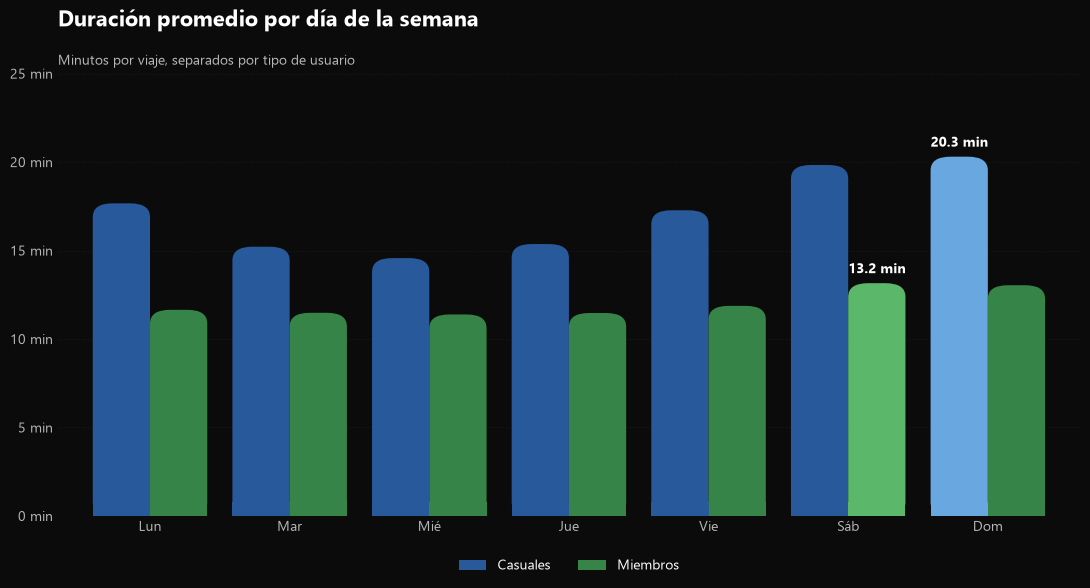

In [110]:

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import FancyBboxPatch, Patch

# 1. ESTILO Y COLORES
plt.style.use("dark_background")
plt.rcParams["font.family"] = "Segoe UI"

azul = "#28599B"
verde = "#378449"
azul_max = "#69A7E1"
verde_max = "#5BB86B"

fondo = "#0B0B0B"
gris_texto = "#B8B8B8"
gris_grilla = "#2A2A2A"

# 2. IDENTIFICAR MÁXIMOS
casual_vals = tabla_promedios["casual"]
member_vals = tabla_promedios["member"]

dia_max_casual = casual_vals.idxmax()
dia_max_member = member_vals.idxmax()

# 3. CREAR GRÁFICO
ax = tabla_promedios.plot(
    kind="bar",
    figsize=(11, 6),
    color=[azul, verde],
    width=0.82,
    edgecolor="none"
)

fig = ax.figure
fig.set_facecolor(fondo)
ax.set_facecolor(fondo)

# 4. REDONDEAR BARRAS Y RESALTAR MÁXIMOS
barras_originales = list(ax.patches)
cantidad_dias = len(tabla_promedios)

for i, barra in enumerate(barras_originales):
    x, y = barra.get_xy()
    ancho = barra.get_width()
    alto = barra.get_height()

    if i < cantidad_dias:
        dia = tabla_promedios.index[i]
        color = azul_max if dia == dia_max_casual else azul
    else:
        dia = tabla_promedios.index[i - cantidad_dias]
        color = verde_max if dia == dia_max_member else verde

    # Calcular redondeo y compensar la escala
    radio = ancho * 0.35

    escala_x = (
        ax.transData.transform((1, 0))[0]
        - ax.transData.transform((0, 0))[0]
    )

    escala_y = (
        ax.transData.transform((0, 1))[1]
        - ax.transData.transform((0, 0))[1]
    )

    relacion_escala = escala_x / escala_y

    nueva_barra = FancyBboxPatch(
        (x, y),
        ancho,
        alto,
        boxstyle=f"round,pad=0,rounding_size={radio}",
        mutation_aspect=relacion_escala,
        facecolor=color,
        edgecolor="none"
    )

    barra.remove()
    ax.add_patch(nueva_barra)

    # Mantener la base recta
    ax.add_patch(
        plt.Rectangle(
            (x, y),
            ancho,
            radio * relacion_escala,
            facecolor=color,
            edgecolor="none"
        )
    )

# 5. TÍTULO Y SUBTÍTULO
ax.set_title(
    "Duración promedio por día de la semana",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=34,
    color="white"
)

ax.text(
    0, 1.02,
    "Minutos por viaje, separados por tipo de usuario",
    transform=ax.transAxes,
    fontsize=10,
    color=gris_texto
)

# 6. EJE X
ax.set_xlabel("")
ax.set_xticks(range(cantidad_dias))
ax.set_xticklabels(
    ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"],
    rotation=0
)

# 7. EJE Y
ax.set_ylabel("")
ax.set_ylim(0, 25)
ax.set_yticks(range(0, 26, 5))

ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda valor, posicion: f"{valor:.0f} min"
    )
)

# 8. GRILLA HORIZONTAL
ax.yaxis.grid(
    True,
    color=gris_grilla,
    linestyle=":",
    linewidth=0.8,
    alpha=0.45
)
ax.set_axisbelow(True)

# 9. QUITAR BORDES
for borde in ax.spines.values():
    borde.set_visible(False)

ax.tick_params(axis="x", length=0, colors=gris_texto)
ax.tick_params(axis="y", length=0, colors=gris_texto)

# 10. LEYENDA
leyenda = [
    Patch(facecolor=azul, label="Casuales"),
    Patch(facecolor=verde, label="Miembros")
]

ax.legend(
    handles=leyenda,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.07),
    ncol=2,
    frameon=False
)

# 11. ETIQUETAR SOLO LOS MÁXIMOS
# Usamos el centro real de cada barra
for columna, inicio in [
    ("casual", 0),
    ("member", cantidad_dias)
]:
    valores = tabla_promedios[columna]
    dia_max = valores.idxmax()
    valor_max = valores.max()

    posicion = tabla_promedios.index.get_loc(dia_max)
    barra = barras_originales[inicio + posicion]

    centro_x = barra.get_x() + barra.get_width() / 2

    ax.text(
        centro_x,
        valor_max + 0.4,
        f"{valor_max:.1f} min",
        ha="center",
        va="bottom",
        color="white",
        fontsize=10,
        fontweight="bold"
    )

# 12. GUARDAR Y MOSTRAR
plt.tight_layout()

plt.savefig(
    "../visualizations/duracion_promedio_por_dia_v2.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()


### Hallazgo 1 — Diferencias en la duración de los viajes

Durante el período analizado (octubre de 2025 a septiembre de 2026), los viajes de usuarios casuales presentaron una duración promedio superior a los de miembros anuales en todos los días de la semana.

Las duraciones promedio más elevadas se registraron durante los fines de semana:

- **Casuales:** alcanzaron su máximo el domingo, con aproximadamente **20,3 minutos por viaje**.
- **Miembros:** alcanzaron su máximo el sábado, con aproximadamente **13,2 minutos por viaje**.

**Interpretación:** estos resultados son compatibles con patrones de uso más recreativos entre los usuarios casuales y más rutinarios entre los miembros anuales. Sin embargo, la duración por sí sola no permite determinar el propósito de cada viaje.

**Implicación comercial:** las diferencias observadas podrían orientar campañas que comuniquen los beneficios de una membresía anual a usuarios casuales frecuentes, especialmente durante los fines de semana. La conveniencia económica de una membresía dependerá de la frecuencia real de uso y de las condiciones tarifarias.

**Nota metodológica:** para calcular las duraciones promedio se excluyeron los viajes superiores a 24 horas, siguiendo el criterio documentado durante la limpieza. Esta exclusión no se aplicó a los demás análisis de volumen de viajes.

### 4.2. Distribución de viajes según hora de inicio

In [111]:
viajes_por_hora = viajes_finales.groupby(['hora_inicio','member_casual']).size()


In [112]:
tabla_horarios = viajes_por_hora.unstack(level=1)
tabla_horarios.columns.name = None
tabla_horarios

,casual,member
hora_inicio,,
0,48700,38208
1,31945,23351
2,20024,13719
3,11758,9061
4,9214,9958
5,14614,38679
6,30227,112561
7,53795,221589
8,77395,287707


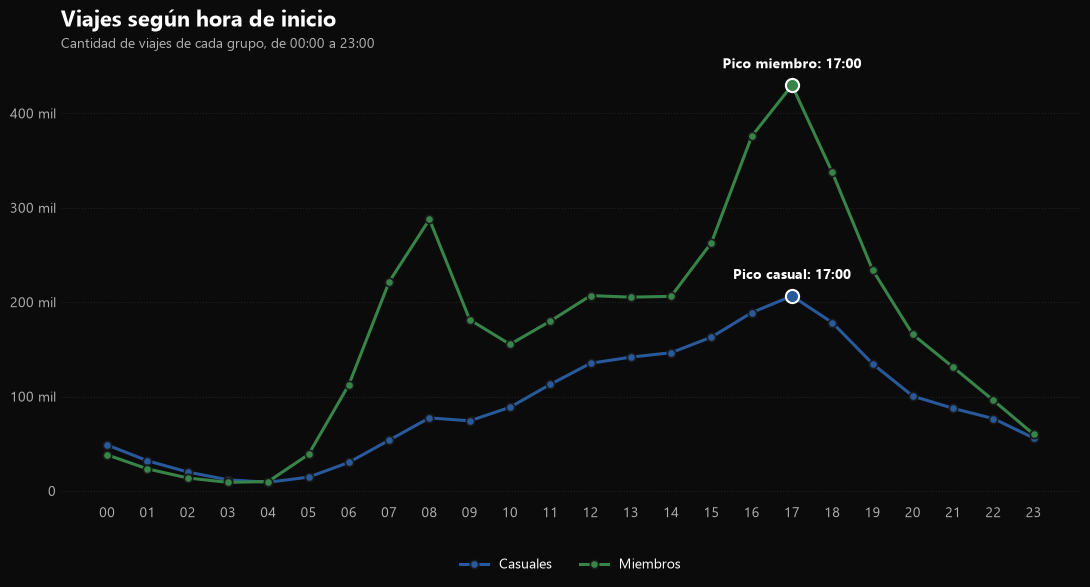

In [113]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Estilo general
plt.style.use("dark_background")
plt.rcParams["font.family"] = "Segoe UI"

# Colores
azul = "#28599B"
verde = "#378449"
fondo = "#0B0B0B"
gris_texto = "#B0B0B0"
gris_grilla = "#454545"

# Crear figura
fig, ax = plt.subplots(figsize=(11, 6))
fig.set_facecolor(fondo)
ax.set_facecolor(fondo)

# Datos
x = tabla_horarios.index
y_casual = tabla_horarios["casual"]
y_member = tabla_horarios["member"]

# Líneas con puntos más visibles
ax.plot(
    x, y_casual,
    color=azul,
    linewidth=2.2,
    marker="o",
    markersize=6,
    markerfacecolor=azul,
    markeredgecolor="#1a1a1a",
    markeredgewidth=1.2,
    label="Casuales"
)

ax.plot(
    x, y_member,
    color=verde,
    linewidth=2.2,
    marker="o",
    markersize=6,
    markerfacecolor=verde,
    markeredgecolor="#1a1a1a",
    markeredgewidth=1.2,
    label="Miembros"
)

# Resaltar máximos de cada grupo
hora_max_casual = y_casual.idxmax()
valor_max_casual = y_casual.max()

hora_max_member = y_member.idxmax()
valor_max_member = y_member.max()

ax.scatter(
    hora_max_casual, valor_max_casual,
    s=90, color=azul, edgecolor="white", linewidth=1.5, zorder=5
)

ax.scatter(
    hora_max_member, valor_max_member,
    s=90, color=verde, edgecolor="white", linewidth=1.5, zorder=5
)

# Etiquetas de esos máximos
ax.text(
    hora_max_casual,
    valor_max_casual + 18000,
    f"Pico casual: {hora_max_casual:02d}:00",
    color="white",
    fontsize=10,
    ha="center",
    fontweight="bold"
)

ax.text(
    hora_max_member,
    valor_max_member + 18000,
    f"Pico miembro: {hora_max_member:02d}:00",
    color="white",
    fontsize=10,
    ha="center",
    fontweight="bold"
)

# Título y subtítulo
ax.set_title(
    "Viajes según hora de inicio",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=28
)

ax.text(
    0, 1.04,
    "Cantidad de viajes de cada grupo, de 00:00 a 23:00",
    transform=ax.transAxes,
    fontsize=10,
    color=gris_texto
)

# Eje X
ax.set_xlabel("")
ax.set_xticks(x)
ax.set_xticklabels([f"{hora:02d}" for hora in x], rotation=0)

# Eje Y
ax.set_ylabel("")
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda valor, pos: f"{int(valor/1000)} mil" if valor != 0 else "0")
)

# Grilla
ax.yaxis.grid(
    True,
    color=gris_grilla,
    linestyle=":",
    linewidth=0.8,
    alpha=0.4
)
ax.xaxis.grid(False)
ax.set_axisbelow(True)

# Quitar bordes
for borde in ax.spines.values():
    borde.set_visible(False)

ax.tick_params(axis="x", length=0, colors=gris_texto)
ax.tick_params(axis="y", length=0, colors=gris_texto)

# Leyenda
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=2,
    frameon=False
)

# Ajustar y guardar
plt.tight_layout()

plt.savefig(
    "../visualizations/viajes_por_hora_inicio.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

### Hallazgo 2 — Diferencias en los horarios de uso

Durante el período analizado (octubre de 2025 a septiembre de 2026), los viajes de usuarios casuales y miembros anuales presentan diferentes patrones según su hora de inicio.

**Principales observaciones:**

- Los miembros anuales presentan dos picos de actividad, alrededor de las **08:00** y las **17:00**.
- Los viajes casuales muestran un crecimiento más gradual a lo largo del día, especialmente durante la tarde.
- Ambos grupos registran su mayor cantidad de viajes iniciados a las **17:00**.

**Comparación porcentual:** el **7,22 % de los viajes de miembros** comienza a las 08:00, frente al **3,54 % de los viajes casuales**. Estos porcentajes se calculan sobre el total de viajes de cada grupo y muestran que la concentración relativa a esa hora es aproximadamente **2,04 veces mayor entre los miembros**.

**Interpretación:** los picos de actividad de los miembros son compatibles con desplazamientos cotidianos vinculados a horarios laborales o educativos. Sin embargo, los registros no permiten identificar directamente el motivo de cada viaje.

**Implicación comercial:** los períodos de mayor actividad casual, especialmente por la tarde, podrían utilizarse para evaluar campañas de conversión. Su efectividad y la conveniencia económica de una membresía deberían validarse con información adicional.

In [114]:
tabla_horarios.div(tabla_horarios.sum()) * 100

,casual,member
hora_inicio,,
0,2.224793,0.959354
1,1.459363,0.586313
2,0.914769,0.344466
3,0.537148,0.227510
4,0.420929,0.250033
5,0.667621,0.971180
6,1.380879,2.826261
7,2.457551,5.563814
8,3.535684,7.223951


### 4.3. Distribución de viajes entre días laborales y fines de semana

In [115]:
viajes_por_dia = viajes_finales.groupby(['member_casual','dia_semana']).size()
viajes_por_dia.unstack(level=0)

member_casual,casual,member
dia_semana,,
Friday,343343,585363
Monday,251669,555734
Saturday,465646,508650
Sunday,351142,418302
Thursday,272227,628677
Tuesday,249688,641191
Wednesday,255253,644765


In [116]:
tabla_viajes_dia = viajes_por_dia.unstack(level=0)
viajes_finde = tabla_viajes_dia.loc[
    ["Saturday", "Sunday"]
].sum()
tabla_viajes_dia

member_casual,casual,member
dia_semana,,
Friday,343343,585363
Monday,251669,555734
Saturday,465646,508650
Sunday,351142,418302
Thursday,272227,628677
Tuesday,249688,641191
Wednesday,255253,644765


In [117]:
viajes_laborales = tabla_viajes_dia.sum() - viajes_finde
viajes_laborales

member_casual
casual    1372180
member    3055730
dtype: int64

In [118]:
tabla_periodos = pd.DataFrame({
    "Días laborales": viajes_laborales,
    "Fin de semana": viajes_finde
})

In [119]:
tabla_periodos

,Días laborales,Fin de semana
member_casual,,
casual,1372180,816788
member,3055730,926952


In [120]:
tabla_periodos.sum(axis=1)

member_casual
casual    2188968
member    3982682
dtype: int64

In [121]:
tabla_periodos.div(tabla_periodos.sum(axis=1), axis=0) * 100

,Días laborales,Fin de semana
member_casual,,
casual,62.686161,37.313839
member,76.725433,23.274567


In [122]:
tabla_porcentajes = tabla_periodos.div(tabla_periodos.sum(axis=1), axis=0) * 100

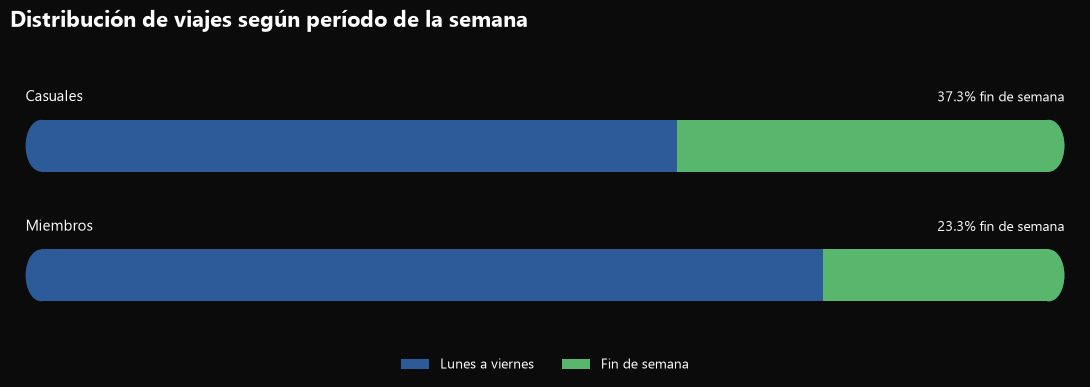

In [123]:

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Ellipse, Patch

# 1. ESTILO
plt.style.use("dark_background")
plt.rcParams["font.family"] = "Segoe UI"

azul = "#2D5B9A"
verde = "#58B66D"
fondo = "#0B0B0B"

# 2. CREAR FIGURA
fig, ax = plt.subplots(figsize=(11, 4))

fig.set_facecolor(fondo)
ax.set_facecolor(fondo)

# 3. CONFIGURACIÓN DE BARRAS
usuarios = ["casual", "member"]
nombres = ["Casuales", "Miembros"]
posiciones = [0.75, 0.25]

alto = 0.20
radio = 1.5  # Curvatura horizontal en puntos porcentuales

for i, usuario in enumerate(usuarios):

    laboral = tabla_porcentajes.loc[usuario, "Días laborales"]
    finde = tabla_porcentajes.loc[usuario, "Fin de semana"]
    y = posiciones[i]
    base = y - alto / 2

    # Fondo azul completo, con extremos redondeados
    ax.add_patch(Rectangle(
        (radio, base),
        100 - 2 * radio,
        alto,
        color=azul,
        linewidth=0
    ))

    for extremo in [radio, 100 - radio]:
        ax.add_patch(Ellipse(
            (extremo, y),
            width=2 * radio,
            height=alto,
            color=azul,
            linewidth=0
        ))

    # Segmento verde con extremo derecho redondeado
    ax.add_patch(Rectangle(
        (laboral, base),
        100 - radio - laboral,
        alto,
        color=verde,
        linewidth=0
    ))

    ax.add_patch(Ellipse(
        (100 - radio, y),
        width=2 * radio,
        height=alto,
        color=verde,
        linewidth=0
    ))

    # Etiquetas superiores
    ax.text(
        0, y + 0.16,
        nombres[i],
        color="white",
        fontsize=11,
        ha="left",
        va="bottom"
    )

    ax.text(
        100, y + 0.16,
        f"{finde:.1f}% fin de semana",
        color="white",
        fontsize=10,
        ha="right",
        va="bottom"
    )

# 4. TÍTULO
ax.set_title(
    "Distribución de viajes según período de la semana",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=24
)

# 5. EJES
ax.set_xlim(-1.5, 101.5)
ax.set_ylim(0.05, 1.08)

ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")

for borde in ax.spines.values():
    borde.set_visible(False)

# 6. LEYENDA
ax.legend(
    handles=[
        Patch(facecolor=azul, label="Lunes a viernes"),
        Patch(facecolor=verde, label="Fin de semana")
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.07),
    ncol=2,
    frameon=False,
    fontsize=10
)

# 7. GUARDAR Y MOSTRAR
plt.tight_layout()

plt.savefig(
    "../visualizations/distribucion_semana.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()


### Hallazgo 3 — Distribución de viajes entre días laborales y fines de semana

Durante el período analizado, el **37,31 % de los viajes casuales** se realizó durante los fines de semana (sábado y domingo), frente al **23,27 % de los viajes de miembros anuales**.

Esto indica que los fines de semana representan una proporción considerablemente mayor de la actividad total de los usuarios casuales.

**Consideración metodológica:** los días laborales comprenden cinco días de la semana, mientras que los fines de semana incluyen solamente dos. Por lo tanto, esta comparación de porcentajes acumulados no permite determinar directamente qué días registran mayor actividad promedio.

Para profundizar el análisis, se calculó posteriormente la cantidad promedio de viajes por día de la semana, teniendo en cuenta las fechas individuales del período.

**Implicación comercial:** los fines de semana podrían representar una oportunidad para campañas dirigidas a usuarios casuales. Sin embargo, antes de priorizar una inversión publicitaria, es necesario considerar el volumen promedio diario de viajes y evaluar la efectividad real de las campañas.

In [124]:
viajes_finales["fecha"] = viajes_finales["started_at"].dt.date

### 4.4. Promedio diario de viajes por día de la semana

In [125]:
viajes_por_fecha = viajes_finales.groupby(['fecha','member_casual']).size()

In [126]:
viajes_por_fecha.unstack(level=1)

member_casual,casual,member
fecha,,
2025-10-01,7879,17821
2025-10-02,8636,17734
2025-10-03,9594,16118
2025-10-04,14445,15261
2025-10-05,11032,12617
...,...,...
2026-09-26,13309,15443
2026-09-27,11149,13477
2026-09-28,8741,17456


In [127]:
tabla_diaria = viajes_por_fecha.unstack(level=1).fillna(0)

In [128]:
tabla_diaria.index = pd.to_datetime(tabla_diaria.index)

In [129]:
tabla_diaria['dia_semana'] = tabla_diaria.index.day_name()

In [130]:
promedio_diario = tabla_diaria.groupby("dia_semana")[["casual", "member"]].mean()

promedio_diario.reindex(orden_dias).round(0).astype(int)

member_casual,casual,member
dia_semana,,
Monday,4840,10687
Tuesday,4802,12331
Wednesday,4816,12165
Thursday,5235,12090
Friday,6603,11257
Saturday,8955,9782
Sunday,6753,8044


In [131]:
promedio_diario = promedio_diario.reindex(orden_dias)

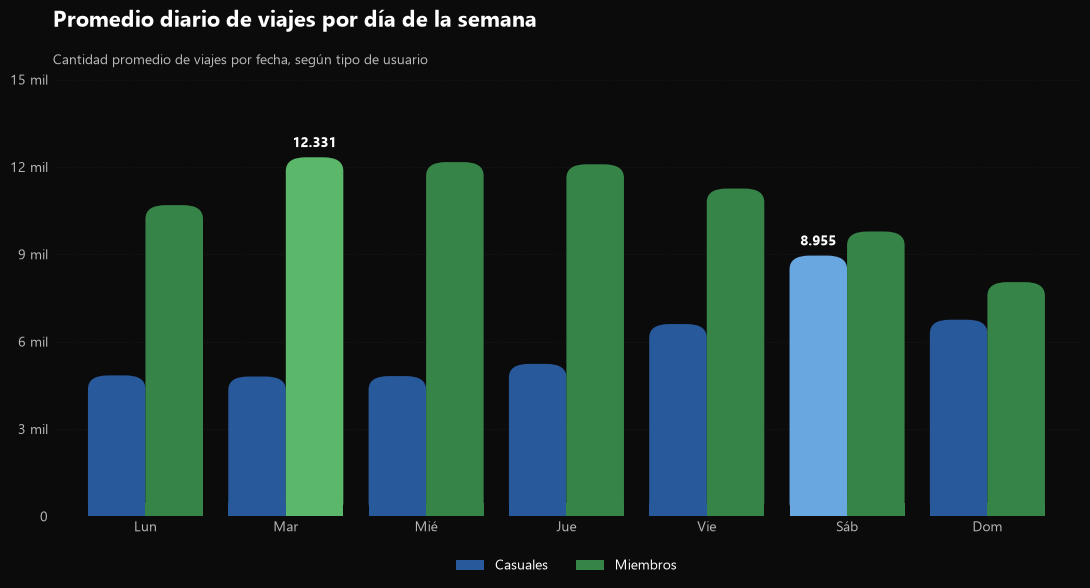

In [132]:

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import FancyBboxPatch, Patch

# 1. ESTILO Y COLORES
plt.style.use("dark_background")
plt.rcParams["font.family"] = "Segoe UI"

azul = "#28599B"
verde = "#378449"
azul_max = "#69A7E1"
verde_max = "#5BB86B"
fondo = "#0B0B0B"

# 2. PREPARAR LOS DATOS
orden_dias = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

datos = promedio_diario.reindex(orden_dias)

# 3. CREAR EL GRÁFICO
ax = datos.plot(
    kind="bar",
    figsize=(11, 6),
    color=[azul, verde],
    width=0.82,
    edgecolor="none"
)

fig = ax.figure
fig.set_facecolor(fondo)
ax.set_facecolor(fondo)

# 4. IDENTIFICAR LOS MÁXIMOS
max_casual = datos["casual"].idxmax()
max_member = datos["member"].idxmax()

# 5. REDONDEAR LAS ESQUINAS SUPERIORES
barras_originales = list(ax.patches)
cantidad_dias = len(datos)

for i, barra in enumerate(barras_originales):

    x, y = barra.get_xy()
    ancho = barra.get_width()
    alto = barra.get_height()

    # Identificar tipo de usuario y resaltar su máximo
    if i < cantidad_dias:
        dia = datos.index[i]
        color = azul_max if dia == max_casual else azul
    else:
        dia = datos.index[i - cantidad_dias]
        color = verde_max if dia == max_member else verde

    # Calcular redondeo y compensar la escala del gráfico
    radio = ancho * 0.35

    escala_x = ax.transData.transform((1, 0))[0] - ax.transData.transform((0, 0))[0]
    escala_y = ax.transData.transform((0, 1))[1] - ax.transData.transform((0, 0))[1]

    relacion_escala = escala_x / escala_y

    barra_redondeada = FancyBboxPatch(
        (x, y),
        ancho,
        alto,
        boxstyle=f"round,pad=0,rounding_size={radio}",
        mutation_aspect=relacion_escala,
        facecolor=color,
        edgecolor="none"
    )

    barra.remove()
    ax.add_patch(barra_redondeada)

    # Mantener la base recta
    ax.add_patch(
        plt.Rectangle(
            (x, y),
            ancho,
            radio * relacion_escala,
            facecolor=color,
            edgecolor="none"
        )
    )

# 6. TÍTULO Y SUBTÍTULO
ax.set_title(
    "Promedio diario de viajes por día de la semana",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=38
)

ax.text(
    0, 1.035,
    "Cantidad promedio de viajes por fecha, según tipo de usuario",
    transform=ax.transAxes,
    fontsize=10,
    color="#B8B8B8"
)

# 7. EJE X
ax.set_xlabel("")
ax.set_xticks(range(cantidad_dias))
ax.set_xticklabels(
    ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"],
    rotation=0
)

# 8. EJE Y
ax.set_ylabel("")
ax.set_ylim(0, 15000)
ax.set_yticks(range(0, 15001, 3000))

ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda valor, posicion:
        f"{valor/1000:.0f} mil" if valor != 0 else "0"
    )
)

# 9. GRILLA HORIZONTAL
ax.yaxis.grid(
    True,
    color="#2A2A2A",
    linestyle=":",
    linewidth=0.8,
    alpha=0.45
)
ax.set_axisbelow(True)

# 10. QUITAR BORDES
for borde in ax.spines.values():
    borde.set_visible(False)

ax.tick_params(axis="both", length=0, colors="#B8B8B8")

# 11. LEYENDA
leyenda = [
    Patch(facecolor=azul, label="Casuales"),
    Patch(facecolor=verde, label="Miembros")
]

ax.legend(
    handles=leyenda,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.07),
    ncol=2,
    frameon=False
)

# 12. ETIQUETAR LOS MÁXIMOS
# Usamos el centro real de cada barra para evitar errores
for columna, inicio in [
    ("casual", 0),
    ("member", cantidad_dias)
]:

    valores = datos[columna]
    dia_max = valores.idxmax()
    valor_max = valores.max()

    posicion = datos.index.get_loc(dia_max)
    barra = barras_originales[inicio + posicion]

    centro_x = barra.get_x() + barra.get_width() / 2

    ax.text(
        centro_x,
        valor_max + 250,
        f"{valor_max:,.0f}".replace(",", "."),
        ha="center",
        va="bottom",
        color="white",
        fontsize=10,
        fontweight="bold"
    )

# 13. GUARDAR Y MOSTRAR
plt.tight_layout()

plt.savefig(
    "../visualizations/promedio_diario_por_dia.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()


### Hallazgo 4: diferencias en la actividad diaria según el tipo de usuario

Para complementar el análisis de días laborales y fines de semana, se calculó el promedio diario de viajes para cada día de la semana, utilizando las fechas individuales del período comprendido entre octubre de 2025 y septiembre de 2026.

**Principales resultados:**

- **Usuarios casuales:** el sábado presenta el mayor promedio, con aproximadamente **8.955 viajes diarios**, seguido por el domingo con **6.753 viajes**.
- **Miembros anuales:** el martes registra el mayor promedio, con aproximadamente **12.331 viajes diarios**, seguido por el miércoles y el jueves.
- La actividad de los usuarios casuales en un sábado promedio es aproximadamente **86 % superior** a la de esos mismos usuarios en un martes promedio.
- Los miembros realizan más viajes diarios que los casuales durante toda la semana, aunque la diferencia entre ambos grupos se reduce notablemente los sábados.

**Interpretación:** los resultados refuerzan la hipótesis de que los usuarios casuales presentan un patrón de uso más concentrado en actividades de fin de semana, mientras que los miembros muestran una mayor actividad durante los días laborales.

**Implicación comercial:** los sábados aparecen como un momento especialmente relevante para campañas de conversión dirigidas a usuarios casuales, debido a su mayor volumen promedio de viajes. Sin embargo, la efectividad de estas campañas debería evaluarse mediante métricas de conversión y costos publicitarios.

**Nota metodológica:** a diferencia del análisis anterior, que comparaba volúmenes acumulados entre cinco días laborales y dos de fin de semana, este cálculo utiliza los viajes registrados en cada fecha y obtiene el promedio para cada día de la semana. Esto permite realizar una comparación más equilibrada entre lunes y domingo.

### 4.5. Análisis geográfico de estaciones prioritarias

In [133]:
viajes_finales.groupby(
    ["start_station_name", "member_casual"]
).size()

start_station_name                     member_casual
11th St Ped Bridge                     casual             1
2112 W Peterson Ave                    casual           254
                                       member           577
21st St & Pulaski Rd                   casual            58
                                       member            33
                                                       ... 
Yates Blvd & 75th St                   member            85
Yates Blvd & 93rd St                   casual            23
                                       member            23
[Archived] Wilton Ave & Diversey Pkwy  casual            28
                                       member           146
Length: 3765, dtype: int64

In [134]:
viajes_por_estacion = viajes_finales.groupby(
    ["start_station_name", "member_casual"]
).size()

In [135]:
tabla_estaciones = viajes_por_estacion.unstack(level=1).fillna(0)

In [136]:
tabla_estaciones["total_viajes"] = (
    tabla_estaciones["casual"] + tabla_estaciones["member"]
)

In [137]:
tabla_estaciones.head()

member_casual,casual,member,total_viajes
start_station_name,,,
11th St Ped Bridge,1.0,0.0,1.0
2112 W Peterson Ave,254.0,577.0,831.0
21st St & Pulaski Rd,58.0,33.0,91.0
63rd St Beach,866.0,423.0,1289.0
900 W Harrison St,2647.0,5955.0,8602.0


In [138]:
tabla_estaciones["porcentaje_casual"] = (tabla_estaciones["casual"] / tabla_estaciones ["total_viajes"] * 100)

In [139]:
tabla_estaciones.head()

member_casual,casual,member,total_viajes,porcentaje_casual
start_station_name,,,,
11th St Ped Bridge,1.0,0.0,1.0,100.000000
2112 W Peterson Ave,254.0,577.0,831.0,30.565584
21st St & Pulaski Rd,58.0,33.0,91.0,63.736264
63rd St Beach,866.0,423.0,1289.0,67.183863
900 W Harrison St,2647.0,5955.0,8602.0,30.771914


In [140]:
estaciones_relevantes = tabla_estaciones[tabla_estaciones["total_viajes"] >= 5000]

In [141]:
estaciones_relevantes.shape

(335, 4)

In [142]:
estaciones_relevantes.sort_values("casual", ascending=False)

member_casual,casual,member,total_viajes,porcentaje_casual
start_station_name,,,,
Navy Pier,50496.0,16088.0,66584.0,75.838039
DuSable Lake Shore Dr & Monroe St,29140.0,7954.0,37094.0,78.557179
Michigan Ave & Oak St,21019.0,13719.0,34738.0,60.507226
DuSable Lake Shore Dr & North Blvd,17292.0,14325.0,31617.0,54.692096
Millennium Park,17175.0,8556.0,25731.0,66.748280
...,...,...,...,...
Wolcott Ave & Polk St,1381.0,6483.0,7864.0,17.561038
Artesian Ave & Hubbard St,1356.0,4030.0,5386.0,25.176383
Larrabee St & Menomonee St,1355.0,4310.0,5665.0,23.918800


In [143]:
top_estaciones = estaciones_relevantes.sort_values(
    "casual",
    ascending=False
).head(10)

top_estaciones

member_casual,casual,member,total_viajes,porcentaje_casual
start_station_name,,,,
Navy Pier,50496.0,16088.0,66584.0,75.838039
DuSable Lake Shore Dr & Monroe St,29140.0,7954.0,37094.0,78.557179
Michigan Ave & Oak St,21019.0,13719.0,34738.0,60.507226
DuSable Lake Shore Dr & North Blvd,17292.0,14325.0,31617.0,54.692096
Millennium Park,17175.0,8556.0,25731.0,66.748280
Shedd Aquarium,16363.0,3698.0,20061.0,81.566223
Theater on the Lake,14969.0,11403.0,26372.0,56.760959
Dusable Harbor,13919.0,5451.0,19370.0,71.858544
Field Museum,10296.0,2409.0,12705.0,81.038961


In [144]:
viajes_navy_pier = viajes_finales[
    viajes_finales["start_station_name"] == "Navy Pier"
]

In [145]:
tabla_navy_pier = viajes_navy_pier.groupby(['dia_semana','member_casual']).size().unstack().reindex(orden_dias)

In [146]:
estaciones_objetivo = [
    "Navy Pier",
    "Shedd Aquarium",
    "DuSable Lake Shore Dr & Monroe St"
]

viajes_estaciones_objetivo = viajes_finales[
    viajes_finales["start_station_name"].isin(estaciones_objetivo)
]

In [147]:
viajes_estaciones_objetivo["start_station_name"].value_counts()

start_station_name
Navy Pier                            66584
DuSable Lake Shore Dr & Monroe St    37094
Shedd Aquarium                       20061
Name: count, dtype: int64

In [148]:
tabla_estaciones_objetivo = viajes_estaciones_objetivo.groupby(
    ["start_station_name", "dia_semana", "member_casual"]
).size()
tabla_estaciones_objetivo.unstack(level=2).reindex(orden_dias,level='dia_semana')

member_casual                                 casual  member
start_station_name                dia_semana                
DuSable Lake Shore Dr & Monroe St Monday        3480     851
                                  Tuesday       2385     937
                                  Wednesday     2423     990
                                  Thursday      2832     906
                                  Friday        4469    1050
                                  Saturday      7756    1786
                                  Sunday        5795    1434
Navy Pier                         Monday        6171    1956
                                  Tuesday       4660    2247
                                  Wednesday     4189    2159
                                  Thursday      4687    2023
                                  Friday        8156    2193
                                  Saturday     13442    3108
                                  Sunday        9191    2402
Shedd Aquarium                    Monday        1765     433
                                  Tuesday       1775     481
                                  Wednesday     1684     649
                                  Thursday      1562     436
                                  Friday        2544     422
                                  Saturday      4131     733
                                  Sunday        2902     544

In [149]:
viajes_casuales_estaciones = viajes_estaciones_objetivo[
    viajes_estaciones_objetivo["member_casual"] == "casual"
]

In [150]:
dias_objetivo = ["Saturday", "Sunday"]

viajes_casuales_finde = viajes_casuales_estaciones[
    viajes_casuales_estaciones["dia_semana"].isin(dias_objetivo)
]


In [151]:
viajes_casuales_finde["dia_semana"].value_counts()

dia_semana
Saturday    25329
Sunday      17888
Name: count, dtype: int64

In [152]:
viajes_finde_por_estacion = viajes_casuales_finde.groupby(
    "start_station_name"
).size()

viajes_finde_por_estacion

start_station_name
DuSable Lake Shore Dr & Monroe St    13551
Navy Pier                            22633
Shedd Aquarium                        7033
dtype: int64

In [153]:
total_casuales_por_estacion = viajes_casuales_estaciones.groupby(
    "start_station_name"
).size()

total_casuales_por_estacion

start_station_name
DuSable Lake Shore Dr & Monroe St    29140
Navy Pier                            50496
Shedd Aquarium                       16363
dtype: int64

In [154]:
porcentaje_finde_por_estacion = (
    viajes_finde_por_estacion / total_casuales_por_estacion
) * 100

porcentaje_finde_por_estacion

start_station_name
DuSable Lake Shore Dr & Monroe St    46.503089
Navy Pier                            44.821372
Shedd Aquarium                       42.981116
dtype: float64

In [155]:
tabla_comparativa_final = pd.DataFrame({
    "viajes_casuales": total_casuales_por_estacion,
    "porcentaje_casual": tabla_estaciones["porcentaje_casual"],
    "porcentaje_finde": porcentaje_finde_por_estacion
})

In [156]:
tabla_comparativa_final = tabla_comparativa_final.loc[
    estaciones_objetivo
]

tabla_comparativa_final = tabla_comparativa_final.sort_values(
    "viajes_casuales",
    ascending=False
)

tabla_comparativa_final = tabla_comparativa_final.round(2)

tabla_comparativa_final

,viajes_casuales,porcentaje_casual,porcentaje_finde
start_station_name,,,
Navy Pier,50496.0,75.84,44.82
DuSable Lake Shore Dr & Monroe St,29140.0,78.56,46.50
Shedd Aquarium,16363.0,81.57,42.98


In [157]:
tabla_comparativa_final.to_csv(
    "../data/processed/comparacion_estaciones.csv",
    index=True
)

In [158]:
from pathlib import Path

Path("../data/processed/comparacion_estaciones.csv").exists()

True

In [159]:
import pandas as pd

tabla_comparativa_final = pd.read_csv(
    "../data/processed/comparacion_estaciones.csv",
    index_col=0
)

tabla_comparativa_final

,viajes_casuales,porcentaje_casual,porcentaje_finde
start_station_name,,,
Navy Pier,50496.0,75.84,44.82
DuSable Lake Shore Dr & Monroe St,29140.0,78.56,46.50
Shedd Aquarium,16363.0,81.57,42.98


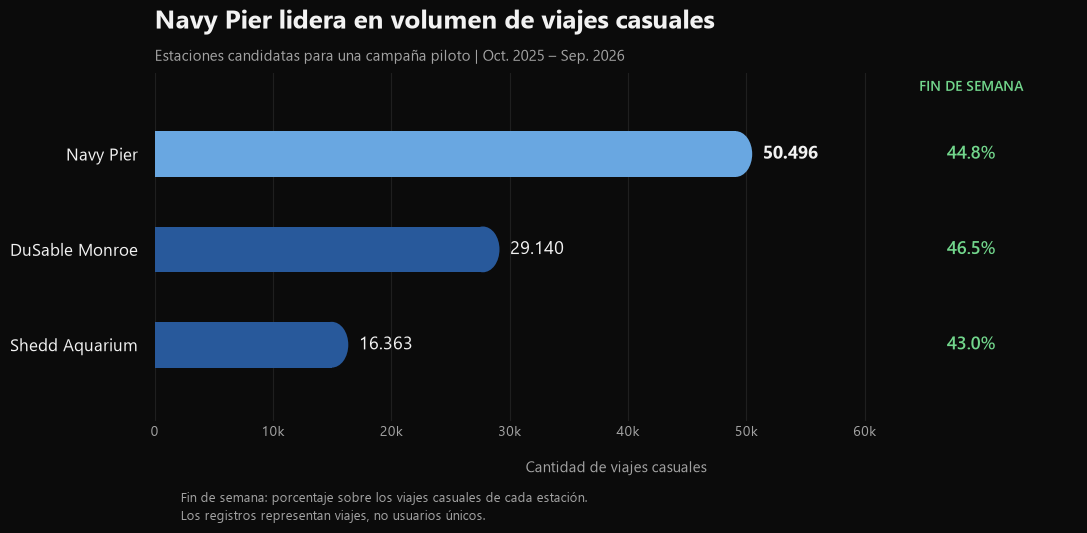

In [160]:

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Ellipse
import numpy as np

# --------------------------------------------------
# 1. PREPARAR LOS DATOS
# --------------------------------------------------

datos_grafico = tabla_comparativa_final.sort_values(
    "viajes_casuales", ascending=True
)

estaciones = {
    "Navy Pier": "Navy Pier",
    "DuSable Lake Shore Dr & Monroe St": "DuSable Monroe",
    "Shedd Aquarium": "Shedd Aquarium"
}

nombres = [
    estaciones.get(nombre, nombre)
    for nombre in datos_grafico.index
]

valores = datos_grafico["viajes_casuales"].values
porcentajes = datos_grafico["porcentaje_finde"].values

# --------------------------------------------------
# 2. ESTILO
# --------------------------------------------------

fondo = "#0B0B0B"
azul = "#28599B"
azul_destacado = "#69A7E1"
verde = "#72D68C"
texto = "#F2F2F2"
gris = "#A3A3A3"

plt.rcParams["font.family"] = "Segoe UI"

fig, ax = plt.subplots(figsize=(13, 6))

fig.patch.set_facecolor(fondo)
ax.set_facecolor(fondo)

posiciones = np.arange(len(nombres))

alto = 0.48
radio = 1400

# Reservamos espacio a la derecha para los porcentajes
ax.set_xlim(0, 78000)
ax.set_ylim(-0.8, len(nombres) - 0.15)

# --------------------------------------------------
# 3. BARRAS Y ETIQUETAS
# --------------------------------------------------

for i, (nombre, valor, pct) in enumerate(
    zip(nombres, valores, porcentajes)
):

    destacado = nombre == "Navy Pier"

    color = azul_destacado if destacado else azul

    # Cuerpo de la barra: inicio cuadrado
    ax.add_patch(Rectangle(
        (0, i - alto / 2),
        valor - radio,
        alto,
        facecolor=color,
        linewidth=0,
        zorder=3
    ))

    # Extremo derecho redondeado
    ax.add_patch(Ellipse(
        (valor - radio, i),
        width=2 * radio,
        height=alto,
        facecolor=color,
        linewidth=0,
        zorder=3
    ))

    # Cantidad de viajes casuales
    ax.text(
        valor + 900,
        i,
        f"{valor:,.0f}".replace(",", "."),
        va="center",
        ha="left",
        fontsize=13,
        fontweight="bold" if destacado else "normal",
        color=texto
    )

    # Porcentaje de fin de semana: columna derecha
    ax.text(
        69000,
        i,
        f"{pct:.1f}%",
        ha="center",
        va="center",
        fontsize=13,
        fontweight="semibold",
        color=verde
    )

# Encabezado de la columna de porcentajes
ax.text(
    69000,
    2.7,
    "FIN DE SEMANA",
    ha="center",
    va="center",
    fontsize=10,
    fontweight="semibold",
    color=verde
)

# --------------------------------------------------
# 4. EJES Y CUADRÍCULA
# --------------------------------------------------

ax.set_yticks(posiciones)
ax.set_yticklabels(
    nombres,
    color=texto,
    fontsize=12
)

ax.tick_params(
    axis="y",
    length=0,
    pad=12
)

ax.tick_params(
    axis="x",
    colors=gris,
    labelsize=10,
    length=0
)

ax.set_xticks([
    0, 10000, 20000, 30000,
    40000, 50000, 60000
])

ax.set_xticklabels([
    "0", "10k", "20k", "30k",
    "40k", "50k", "60k"
])

ax.grid(
    axis="x",
    color="#333333",
    alpha=0.5,
    zorder=0
)

for spine in ax.spines.values():
    spine.set_visible(False)

# --------------------------------------------------
# 5. TÍTULOS
# --------------------------------------------------

ax.set_title(
    "Navy Pier lidera en volumen de viajes casuales",
    loc="left",
    color=texto,
    fontsize=19,
    fontweight="bold",
    pad=32
)

ax.text(
    0,
    1.035,
    "Estaciones candidatas para una campaña piloto | Oct. 2025 – Sep. 2026",
    transform=ax.transAxes,
    color=gris,
    fontsize=11
)

ax.set_xlabel(
    "Cantidad de viajes casuales",
    color=gris,
    fontsize=11,
    labelpad=16
)

# --------------------------------------------------
# 6. NOTAS METODOLÓGICAS
# --------------------------------------------------

fig.text(
    0.27,
    0.085,
    "Fin de semana: porcentaje sobre los viajes casuales de cada estación.",
    color=gris,
    fontsize=9
)

fig.text(
    0.27,
    0.055,
    "Los registros representan viajes, no usuarios únicos.",
    color=gris,
    fontsize=9
)

# --------------------------------------------------
# 7. GUARDAR Y MOSTRAR
# --------------------------------------------------

plt.subplots_adjust(
    left=0.25,
    right=0.96,
    top=0.80,
    bottom=0.22
)

plt.savefig(
    "../visualizations/estaciones_prioritarias.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()


### Análisis geográfico: identificación de oportunidades de marketing

Se compararon tres estaciones con un elevado volumen de viajes casuales: Navy Pier, DuSable Lake Shore Dr & Monroe St y Shedd Aquarium.

**Navy Pier destaca como principal candidata para una campaña piloto**, con 50.496 viajes casuales durante el período analizado. El 75,84 % de sus viajes corresponde a usuarios casuales y aproximadamente el 44,82 % de esos viajes ocurre durante los fines de semana.

Aunque DuSable Lake Shore Dr & Monroe St registra una mayor concentración de viajes casuales durante los fines de semana (46,50 %) y Shedd Aquarium presenta la mayor proporción de viajes casuales sobre el total de la estación (81,57 %), Navy Pier ofrece el mayor volumen absoluto de actividad casual entre las tres ubicaciones.

**Recomendación:** implementar una campaña piloto de promoción de membresías anuales en Navy Pier, con especial atención a los fines de semana. La efectividad deberá evaluarse mediante conversiones medibles y, preferentemente, un grupo de control.

Si la campaña demuestra resultados positivos, se recomienda considerar su expansión a DuSable Lake Shore Dr & Monroe St y Shedd Aquarium.

**Limitación:** los registros representan viajes, no usuarios únicos. Por lo tanto, el volumen observado no permite determinar directamente el número de potenciales clientes ni anticipar la tasa de conversión.

### 4.6. Síntesis final de los hallazgos

El análisis de los viajes de Cyclistic entre octubre de 2025 y septiembre de 2026 permitió identificar diferencias relevantes en los patrones de uso entre usuarios casuales y miembros anuales.

**1. Duración de los viajes.** Los viajes casuales presentan una duración promedio superior durante todos los días de la semana. Los domingos alcanzan aproximadamente **20,3 minutos**, mientras que los miembros registran su máximo los sábados, con **13,2 minutos**.

**2. Horarios de uso.** Los miembros presentan picos de actividad a las **08:00 y las 17:00**, compatibles con desplazamientos cotidianos. El 7,22 % de sus viajes comienza a las 08:00, frente al 3,54 % de los viajes casuales.

**3. Distribución semanal.** El **37,31 % de los viajes casuales** ocurre durante los fines de semana, frente al **23,27 % de los viajes de miembros**. Esto refleja una mayor concentración relativa de actividad casual durante sábados y domingos.

**4. Actividad diaria.** Los sábados registran el mayor promedio de viajes casuales, con aproximadamente **8.955 viajes diarios**, mientras que los martes presentan el mayor promedio de miembros, con **12.331 viajes diarios**.

**5. Oportunidades geográficas.** Entre las tres estaciones seleccionadas para la comparación, **Navy Pier registra el mayor volumen de viajes casuales (50.496)**, de los cuales el **44,82 % ocurre durante los fines de semana**. Esto la convierte en una candidata relevante para evaluar una campaña piloto de conversión.

**Conclusión general:** los resultados muestran patrones compatibles con un uso más recreativo entre los usuarios casuales y un uso más vinculado a desplazamientos rutinarios entre los miembros anuales.

Estas diferencias permiten identificar oportunidades de marketing segmentadas por día, horario y ubicación. Sin embargo, los datos representan viajes y no usuarios únicos, por lo que no permiten determinar directamente las motivaciones individuales, la disposición a adquirir una membresía ni las tasas de conversión esperadas.

## 6. Act — Recomendaciones y próximos pasos

### 6.1. Principales recomendaciones comerciales

A partir del análisis de los viajes de Cyclistic entre octubre de 2025 y septiembre de 2026, se proponen tres recomendaciones orientadas a apoyar la conversión de usuarios casuales en miembros anuales.

**1. Implementar una campaña piloto de membresías en Navy Pier**

Navy Pier registró **50.496 viajes casuales**, el mayor volumen entre las tres estaciones seleccionadas. Además, el **44,82 %** de esos viajes ocurrió durante los fines de semana.

Se recomienda implementar una campaña piloto en esta estación, especialmente los sábados y domingos, para evaluar el interés de los usuarios casuales por las membresías anuales.

La efectividad debería medirse mediante conversiones atribuibles a la campaña y, de ser posible, compararse con un grupo de control. Si demuestra resultados positivos, podría ampliarse a DuSable Lake Shore Dr & Monroe St y Shedd Aquarium.

**2. Priorizar los sábados en las acciones de marketing dirigidas a usuarios casuales**

Los sábados presentan el mayor promedio de viajes casuales, con aproximadamente **8.955 viajes diarios**. Este valor es alrededor de un **86 % superior** al promedio casual de los martes.

Se recomienda evaluar acciones publicitarias durante los sábados, cuando se registra la mayor actividad casual promedio, y utilizar horarios de elevada actividad para mejorar las oportunidades de exposición a los mensajes.

La priorización definitiva deberá considerar los costos publicitarios y las conversiones efectivamente obtenidas.

**3. Adaptar la comunicación comercial a los diferentes patrones de uso**

Los usuarios casuales presentan viajes de mayor duración promedio y una concentración relativamente superior de actividad durante los fines de semana. En contraste, los miembros anuales muestran picos de viajes a las **08:00 y las 17:00**, compatibles con desplazamientos cotidianos.

Se recomienda probar mensajes comerciales diferenciados que expliquen los posibles beneficios de una membresía anual para distintos hábitos de uso, incluyendo actividades recreativas frecuentes y desplazamientos regulares.

Las campañas deben comunicar beneficios reales y verificables, considerando las condiciones tarifarias vigentes. No puede asumirse que la membresía sea económicamente conveniente para todos los usuarios casuales.

### 6.2. Conclusión final

El análisis de los viajes de Cyclistic entre octubre de 2025 y septiembre de 2026 permitió identificar diferencias relevantes entre los patrones de uso de miembros anuales y usuarios casuales.

Los usuarios casuales realizan viajes de mayor duración promedio y presentan una mayor concentración relativa de actividad durante los fines de semana, especialmente los sábados. Por su parte, los miembros anuales muestran una actividad más elevada durante los días laborales y picos horarios compatibles con desplazamientos cotidianos.

Estas diferencias sugieren que ambos grupos utilizan el servicio en contextos potencialmente distintos, aunque los registros no permiten identificar directamente el propósito de cada viaje.

Los hallazgos ofrecen una base para diseñar estrategias de marketing segmentadas por ubicación, día de la semana y patrones de uso. En particular, Navy Pier se identifica como una ubicación candidata para evaluar una campaña piloto de conversión de usuarios casuales en miembros anuales.

**En conclusión, el análisis responde a la pregunta principal del caso de estudio y proporciona evidencia para orientar futuras decisiones comerciales.** Sin embargo, la efectividad de las estrategias propuestas deberá comprobarse mediante pruebas y métricas de conversión.

### 6.3. Limitaciones del análisis y próximos pasos

Aunque el análisis permitió identificar diferencias relevantes en los patrones de uso, existen limitaciones que deben considerarse al interpretar los resultados y formular recomendaciones.

**Principales limitaciones:**

- **Ausencia de identificadores de usuario:** los registros representan viajes individuales, por lo que no es posible identificar usuarios casuales recurrentes ni calcular su frecuencia personal de uso.
- **Falta de información sobre tarifas y gastos:** no se dispone de datos suficientes para determinar cuándo una membresía anual sería económicamente conveniente para cada usuario.
- **Motivos de viaje desconocidos:** los patrones temporales y de duración permiten formular hipótesis sobre usos recreativos o cotidianos, pero no comprobar directamente sus motivaciones.
- **Información limitada sobre disponibilidad:** los datos de viajes no permiten evaluar completamente cómo la disponibilidad de bicicletas y estaciones influye en los patrones observados.

**Próximos pasos recomendados:**

1. Realizar una campaña piloto de membresías en Navy Pier, incorporando mecanismos para medir las conversiones y, cuando sea posible, un grupo de control.
2. Evaluar el rendimiento de distintas campañas según día, horario y mensaje publicitario, considerando tanto conversiones como costos.
3. Incorporar información adicional sobre tarifas, disponibilidad y frecuencia individual de uso, siempre que su utilización cumpla las políticas de privacidad correspondientes.
4. Utilizar los resultados de las pruebas para ajustar las estrategias y evaluar una posible expansión hacia otras estaciones con elevada actividad casual.

Estas acciones permitirían complementar el análisis descriptivo con evidencia sobre la efectividad real de las estrategias comerciales propuestas.